# The same function, 1.6 million calls or 31

Recursion lets you write a definition and run it. This notebook shows two things
that follow from how recursion runs: a definition run as written can repeat the
same work an exponential number of times, and every call takes a slot on a
stack that is finite. It ends with the recursive algorithm that does neither,
Euclid's, to show that recursion done right is fast.

## 1. Fibonacci as written, and with memory

The Fibonacci numbers are defined recursively: $F(0) = 0$, $F(1) = 1$ and
$F(n) = F(n-1) + F(n-2)$. We write that definition down twice. The first version
runs it as it is. The second saves every result it computes in a dictionary and
looks there first, which is dynamic programming in its simplest form. Both count
how many times they are called.

In [1]:
import time

calls = 0

def fib_naive(n):
    global calls
    calls += 1
    if n < 2:                       # base case
        return n
    return fib_naive(n - 1) + fib_naive(n - 2)

memo = {}

def fib_memo(n):
    global calls
    calls += 1
    if n < 2:
        return n
    if n not in memo:               # compute each value only once
        memo[n] = fib_memo(n - 1) + fib_memo(n - 2)
    return memo[n]

ns = list(range(5, 31, 5))
naive_calls, naive_time, memo_calls = [], [], []
for n in ns:
    calls = 0; t0 = time.perf_counter(); fib_naive(n)
    naive_time.append(time.perf_counter() - t0); naive_calls.append(calls)
    calls = 0; memo.clear(); fib_memo(n); memo_calls.append(calls)
    print(f"n = {n:2}   as written: {naive_calls[-1]:>9,} calls, {naive_time[-1]:7.3f} s"
          f"   with memory: {memo_calls[-1]:>3} calls")

n =  5   as written:        15 calls,   0.000 s   with memory:   9 calls
n = 10   as written:       177 calls,   0.000 s   with memory:  19 calls
n = 15   as written:     1,973 calls,   0.000 s   with memory:  29 calls
n = 20   as written:    21,891 calls,   0.002 s   with memory:  39 calls
n = 25   as written:   242,785 calls,   0.010 s   with memory:  49 calls
n = 30   as written: 2,692,537 calls,   0.118 s   with memory:  59 calls


The version with memory makes $2n - 1$ calls, one per value plus one per lookup.
The version as written makes more than $1.6^n$ calls, because $F(n-1)$ and
$F(n-2)$ both recompute $F(n-3)$, which both recompute $F(n-4)$, and so on down
to the base cases. Every five steps of $n$ the count grows by about a factor of
eleven. Plotted on a logarithmic axis, exponential growth is a straight line.

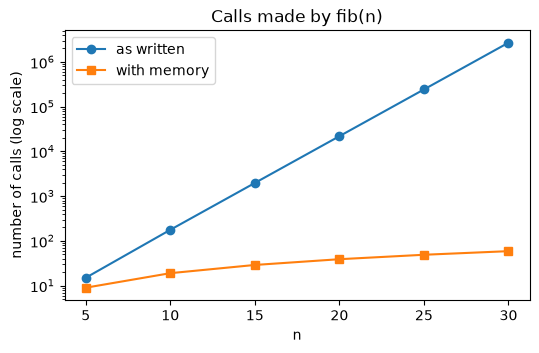

one call takes about 0.04 microseconds
fib_naive(100) would need about 1,096,749 years


In [2]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(ns, naive_calls, "o-", label="as written")
ax.plot(ns, memo_calls, "s-", label="with memory")
ax.set_yscale("log"); ax.set_xlabel("n"); ax.set_ylabel("number of calls (log scale)")
ax.legend(); ax.set_title("Calls made by fib(n)")
plt.show()

per_call = naive_time[-1] / naive_calls[-1]
print(f"one call takes about {per_call * 1e6:.2f} microseconds")
print(f"fib_naive(100) would need about {per_call * 1.618 ** 100 / 3.15e7:,.0f} years")

The straight line is the point: doubling the time budget or the speed of the
computer moves you a few steps to the right and no further. Saving results turns
the same definition into a linear algorithm. When a recursive definition calls
itself more than once on overlapping subproblems, look for this.

## 2. The stack is finite

Every call that has not returned yet occupies a frame on the program stack.
Python allows a fixed number of frames, a thousand by default and three thousand
inside Jupyter, and then raises `RecursionError`. This is not a quirk of Python:
every language has a limit, only the number differs.

A depth-first search written recursively goes as deep as the longest path it
follows. On a chain of 5 000 people, each connected to the next, the recursive
version fails before it reaches the end. The iterative version keeps its own
stack in a list, which lives in ordinary memory and can hold millions of
entries.

In [3]:
import sys
print("recursion limit:", sys.getrecursionlimit())

n = 5_000
neighbors = {i: [i + 1] if i + 1 < n else [] for i in range(n)}   # a chain 0 - 1 - 2 - ... - 4999

def dfs_recursive(u, seen):
    seen.add(u)
    for v in neighbors[u]:
        if v not in seen:
            dfs_recursive(v, seen)

def dfs_iterative(start):
    seen, stack = set(), [start]        # our own stack, on the heap
    while stack:
        u = stack.pop()
        if u not in seen:
            seen.add(u)
            stack.extend(v for v in neighbors[u] if v not in seen)
    return seen

try:
    seen = set(); dfs_recursive(0, seen)
    print("recursive DFS reached", len(seen), "nodes")
except RecursionError:
    print("recursive DFS: RecursionError, reached", len(seen), "nodes before failing")

print("iterative DFS reached", len(dfs_iterative(0)), "nodes")

recursion limit: 3000
recursive DFS: RecursionError, reached 2977 nodes before failing
iterative DFS reached 5000 nodes


The recursive search stops a little short of the limit, the iterative one
finishes. A recursive algorithm is correct at every depth on paper and only up to
a fixed depth on a real machine; for trees that are shallow, such as balanced
search trees or the mergesort recursion, the depth is $\log_2 n$ and the limit
never matters, but on long paths it does. You can raise the limit with
`sys.setrecursionlimit`, which only moves the wall.

## 3. Recursion done right: Euclid

Not every recursive algorithm is expensive. Euclid's algorithm for the greatest
common divisor, $\gcd(a, b) = \gcd(b, a \bmod b)$, calls itself once per step
and the numbers shrink fast. We count the steps for two 18-digit numbers and
compare with the obvious alternative, trying every candidate divisor.

In [4]:
steps = 0

def gcd(a, b):
    global steps
    steps += 1
    return a if b == 0 else gcd(b, a % b)          # one recursive call, no repeated work

a, b = 123_456_789_012_345_678, 987_654_321_098_765_432
steps = 0; g = gcd(a, b)
print(f"gcd = {g}, found in {steps} recursive calls")

# trying every divisor: time it on small numbers and scale up
small_a, small_b = 1_234_567, 7_654_321
t0 = time.perf_counter()
g2 = max(d for d in range(1, min(small_a, small_b) + 1) if small_a % d == 0 and small_b % d == 0)
dt = time.perf_counter() - t0
print(f"trying every divisor up to {min(small_a, small_b):,}: {dt:.2f} s")
print(f"for the 18-digit numbers that would take about {dt * min(a, b) / min(small_a, small_b) / 3.15e7:,.0f} years")

gcd = 2, found in 16 recursive calls
trying every divisor up to 1,234,567: 0.03 s
for the 18-digit numbers that would take about 84 years


Sixteen calls against decades. The number of steps of Euclid's algorithm
grows with the number of digits, not with the size of the numbers, which is why
it is still used inside every program that reduces fractions or generates
cryptographic keys. Recursion is a way of writing algorithms, not a cost in
itself; what costs is repeated work, and what limits you is depth.

**What we used:** the three parts of a recursive definition
([session 6, section 2](../Transcripts/06-Recursion.md#2-the-three-parts-of-a-recursive-definition)),
how recursion runs on the program stack
([section 4](../Transcripts/06-Recursion.md#4-how-recursion-runs-the-program-stack)),
Euclid's algorithm ([section 5](../Transcripts/06-Recursion.md#5-euclids-algorithm)),
depth-first search ([section 6](../Transcripts/06-Recursion.md#6-depth-first-search))
and dynamic programming ([section 8](../Transcripts/06-Recursion.md#8-dynamic-programming)).